In [3]:
library("PRROC")
library("data.table")
library("xgboost")
library("caret")
library("ggplot2")
library("dplyr")
library("knitr")

Loading required package: ggplot2

Loading required package: lattice


Attaching package: ‘dplyr’


The following object is masked from ‘package:xgboost’:

    slice


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [4]:
source("/mnt/nfsp1/nbinit.R")

In [5]:
features = c("DP","ECNT","MBQ_REF","MBQ_ALT","MFRL_REF","MFRL_ALT","MMQ_REF","MMQ_ALT","MPOS","NALOD","NLOD","TLOD",
             "avg_mapping_quality","avg_basequality","avg_pos_as_fraction","avg_num_mismatches_as_fraction","avg_sum_mismatch_qualities")

In [237]:
dtm <- fread("dtm_0819.txt", sep="\t")

In [238]:
unique(dtm$plat)

[1] "FASTASeq_300" "GenoLab_M"    "SURFSeq_5000" "NovaSeq_6000" "NovaSeq_X"   
[6] "MGISEQ-T7"

In [276]:
folds <- createFolds(dtm$label, k = 5, list = TRUE)
      
# 划分训练集和验证集
train_indices <- folds[[1]]
dt_train <- dtm[-train_indices]
print(nrow(dt_train))
dt_test <- dtm[train_indices]
print(nrow(dt_test))

# 准备训练数据
dtrain <- xgb.DMatrix(data = data.matrix(dt_train[, features, with=FALSE]), label = dt_train$label)

# 训练 xgboost 模型
xgb_model <- xgboost(
  data = dtrain, 
  max.depth = 7, 
  eta = 0.1, 
  nthread = 150, 
  nrounds = 400,
  objective = "binary:logistic", 
  verbose = FALSE
)

predictions <- predict(xgb_model, newdata=data.matrix(dt_test[, features, with=FALSE]), type = "prob")
pr_curve <- pr.curve(scores.class0 = predictions, weights.class0 = dt_test$label,curve=T)
pr_auc <- pr_curve$auc.integral

print(pr_auc)

[1] 395150
[1] 98787
[1] 0.9916008


In [277]:
# Released model name in this reproducibility repo
xgb.save(xgb_model, fname="SomaticXGB")
# historical alias used in the original analysis directory:
# xgb.save(xgb_model, fname="model_0820")

[1] TRUE

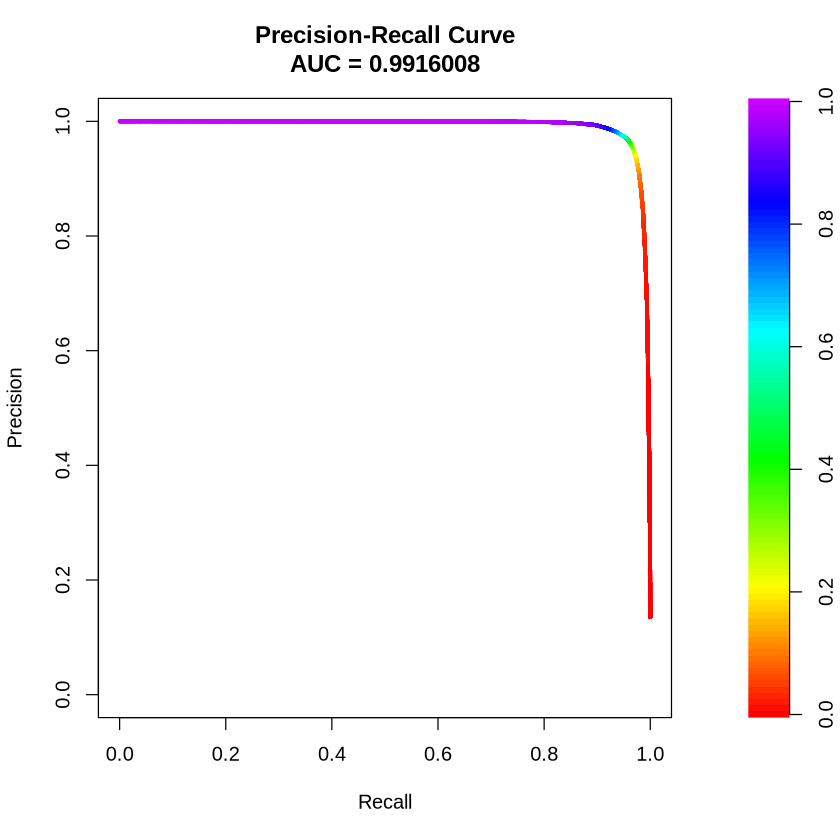

In [278]:
plot(pr_curve, main = "Precision-Recall Curve", xlab = "Recall", ylab = "Precision")

In [18]:
xgb_model <- xgb.load("SomaticXGB")
# or: xgb_model <- xgb.load("model_0820")  # original filename

In [166]:
dt4554 <- fread("240726-train-test/dt_test_45_54.txt", sep="\t")

In [167]:
dt4554$pred <- predict(xgb_model, data.matrix(dt4554[, features, with=FALSE]))

In [168]:
unique(dt4554$plat)

[1] "FASTASeq_300" "GenoLab_M"    "MGISEQ-T7"    "NovaSeq_6000" "NovaSeq_X"   
[6] "SURFSeq_5000"

In [169]:
dt4554[, group := c("45"="HG004-HG005","54"="HG005-HG004")[as.character(group)]]

In [170]:
dt4554$pred <- predict(xgb_model, data.matrix(dt4554[, features, with=FALSE]))

In [195]:
features = c("DP","ECNT","MBQ_REF","MBQ_ALT","MFRL_REF","MFRL_ALT","MMQ_REF","MMQ_ALT","MPOS","NALOD","NLOD","TLOD",
             "avg_mapping_quality","avg_basequality","avg_pos_as_fraction","avg_num_mismatches_as_fraction","avg_sum_mismatch_qualities")

In [172]:
head(dt4554)

var,DP,ECNT,MPOS,NALOD,NLOD,MBQ_REF,MBQ_ALT,MFRL_REF,MFRL_ALT,⋯,label,avg_mapping_quality,avg_basequality,avg_pos_as_fraction,avg_num_mismatches_as_fraction,avg_sum_mismatch_qualities,plat,reads,group,pred
<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,⋯,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<chr>,<dbl>
10:104849468:G:A,3137,2,46,2.04,31.30,20,20,180,180,⋯,1,60,35.84,0.59,0.01,36.75,FASTASeq_300,100,HG004-HG005,0.9976148605
10:104934709:T:C,2651,1,26,1.95,26.04,20,20,185,153,⋯,1,60,35.71,0.46,0.01,36.83,FASTASeq_300,100,HG004-HG005,0.9994431138
10:111967637:C:G,2090,1,33,1.89,22.47,20,36,196,257,⋯,0,60,36.00,0.52,0.01,43.20,FASTASeq_300,100,HG004-HG005,0.0224344693
10:111986037:G:T,704,1,47,1.48,8.73,20,20,164,126,⋯,0,60,36.00,0.76,0.01,39.50,FASTASeq_300,100,HG004-HG005,0.0029898908
10:112724158:A:G,3629,1,31,2.17,43.58,20,20,191,146,⋯,0,60,35.44,0.57,0.01,35.44,FASTASeq_300,100,HG004-HG005,0.0019717463
10:112771361:T:A,1924,1,36,1.84,20.03,20,20,200,164,⋯,0,60,36.00,0.43,0.01,36.00,FASTASeq_300,100,HG004-HG005,0.0008315072


In [196]:
model_nx <- xgb.load("xgb_nx_0823")

In [197]:
importance_nx <- xgb.importance(feature_names = features, model = model_nx)

In [198]:
fwrite(importance_nx, "importance_nx.txt", sep="\t")

In [174]:
predictions <- predict(model_nx, newdata=data.matrix(dt4554[, features, with=FALSE]), type = "prob")
pr_curve <- pr.curve(scores.class0 = predictions, weights.class0 = dt4554$label, curve=T)
# pr_auc_nx <- pr_curve_nx$auc.integral

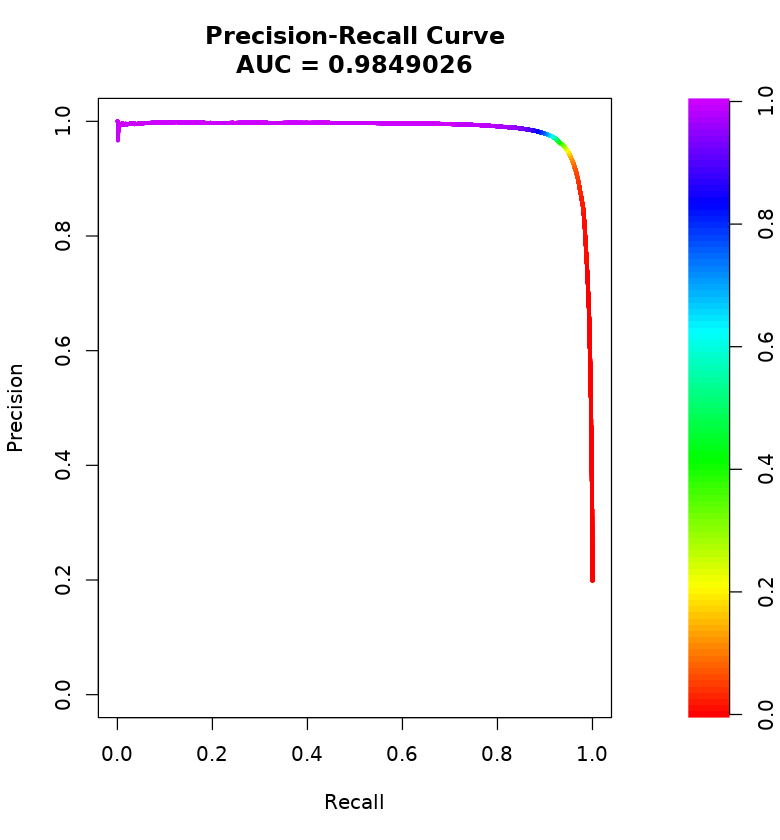

In [175]:
plot(pr_curve, main = "Precision-Recall Curve", xlab = "Recall", ylab = "Precision")

In [159]:
# 生成dt4554的pred列的代码不见了
dt4554_preds <- rbind(dt4554[pred>0.2][, Threshold:=0.2], dt4554[pred>0.1][, Threshold:=0.1], dt4554[pred>0.05][, Threshold:=0.05])

In [160]:
stat <- rbind(fread("240726-train-test/stat45.txt",sep="\t"), fread("240726-train-test/stat54.txt",sep="\t"))

In [161]:
head(stat)

Caller,Reads,Platform,NPos,Nresults,truePos,falsePos,Recall,Precision,F1,Group
<chr>,<int>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>
Strelka2_Mutect2,100,FASTASeq 300,481,361,349,12,0.7256,0.9668,0.8290,HG004-HG005
Strelka2_Mutect2,120,FASTASeq 300,481,400,383,17,0.7963,0.9575,0.8695,HG004-HG005
Strelka2_Mutect2,140,FASTASeq 300,481,391,375,16,0.7796,0.9591,0.8601,HG004-HG005
Strelka2_Mutect2,60,FASTASeq 300,481,322,311,11,0.6466,0.9658,0.7746,HG004-HG005
Strelka2_Mutect2,80,FASTASeq 300,481,353,339,14,0.7048,0.9603,0.8129,HG004-HG005
Strelka2_Mutect2,100,GenoLab M,481,344,324,20,0.6736,0.9419,0.7855,HG004-HG005


In [162]:
unique(stat$Caller)

[1] "Strelka2_Mutect2" "strelka2"         "mutect2"          "VarScan-fpfilter"

In [163]:
setnames(stat, old="Caller", new="Method")

In [164]:
setnames(stat, old="Platform", new="Platforms")

In [34]:
pf45 <- fread("240726-train-test/45/pf45_low.txt")
pf45 <- setnames(pf45,c("CHROM", "POS", "P", "REF","ALT","GT","f","b","GT2","group","AF")) %>% 
.[, CHROM := as.character(CHROM)] %>% 
.[, POS := as.character(POS)] %>% .[, P := NULL] %>%
.[, var := paste(CHROM,POS,REF,ALT,sep=":")]

pf54 <-  fread("240726-train-test/54/pf54_low.txt")
pf54 <- setnames(pf54,c("CHROM", "POS", "P", "REF","ALT","GT","f","b","GT2","group","AF")) %>% 
.[, CHROM := as.character(CHROM)] %>% 
.[, POS := as.character(POS)] %>% .[, P := NULL] %>%
.[, var := paste(CHROM,POS,REF,ALT,sep=":")]

In [50]:
model_stat45 <- dt4554_preds[group=="HG004-HG005"][, .(NPos = nrow(pf45), Nresults = .N, truePos = sum(var %in% pf45$var), falsePos = sum(!var %in% pf45$var)), by = c("reads","plat","Threshold")] %>% 
.[, Recall := round(truePos/NPos,4)] %>%
.[, Precision := round(truePos/Nresults,4)] %>%
.[, F1 := round(2*Recall*Precision/(Recall+Precision),4)]%>%
.[, Group := "HG004-HG005"]

In [36]:
model_stat54 <- dt4554_preds[group=="HG005-HG004"][, .(NPos = nrow(pf54), Nresults = .N, truePos = sum(var %in% pf54$var), falsePos = sum(!var %in% pf54$var)), by = c("reads","plat","Threshold")] %>% 
.[, Recall := round(truePos/NPos,4)] %>%
.[, Precision := round(truePos/Nresults,4)] %>%
.[, F1 := round(2*Recall*Precision/(Recall+Precision),4)]%>%
.[, Group := "HG005-HG004"]

In [296]:
model_stat <- rbind(model_stat45, model_stat54)

In [297]:
model_stat[, Method := paste0("SomaticXGB (threshold: ", Threshold, ")")]

In [298]:
model_stat[, Threshold := NULL]

In [299]:
setnames(model_stat, old=c("reads","plat"), new=c("Reads","Platforms"))

In [300]:
stat_final <- rbind(stat, model_stat)

In [301]:
stat_final <- stat_final[Method != 'strelka2' & Method != 'mutect2']

In [302]:
stat_final[, Reads := factor(Reads)]

In [303]:
fwrite(stat_final, "stat_final_0820.txt", sep="\t")

In [176]:
dt45 <- dt4554[group=='HG004-HG005']

In [177]:
dt45$pred <- predict(model_nx, data.matrix(dt45[, features, with=FALSE]))

In [178]:
dt45_preds <- rbind(dt45[pred>0.2][, Threshold:=0.2], dt45[pred>0.1][, Threshold:=0.1], dt45[pred>0.05][, Threshold:=0.05])

In [179]:
modelnx_stat45 <- dt45_preds[, .(NPos = nrow(pf45), Nresults = .N, truePos = sum(var %in% pf45$var), falsePos = sum(!var %in% pf45$var)), by = c("reads","plat","Threshold")] %>% 
.[, Recall := round(truePos/NPos,4)] %>%
.[, Precision := round(truePos/Nresults,4)] %>%
.[, F1 := round(2*Recall*Precision/(Recall+Precision),4)] %>%
.[, Methods := "Model trained on NovaSeq X data only"]

In [180]:
head(modelnx_stat45)

reads,plat,Threshold,NPos,Nresults,truePos,falsePos,Recall,Precision,F1,Methods
<int>,<chr>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>
100,FASTASeq_300,0.2,481,437,424,13,0.8815,0.9703,0.9238,Model trained on NovaSeq X data only
120,FASTASeq_300,0.2,481,452,439,13,0.9127,0.9712,0.9410,Model trained on NovaSeq X data only
140,FASTASeq_300,0.2,481,445,433,12,0.9002,0.9730,0.9352,Model trained on NovaSeq X data only
60,FASTASeq_300,0.2,481,436,416,20,0.8649,0.9541,0.9073,Model trained on NovaSeq X data only
80,FASTASeq_300,0.2,481,439,424,15,0.8815,0.9658,0.9217,Model trained on NovaSeq X data only
100,GenoLab_M,0.2,481,444,428,16,0.8898,0.9640,0.9254,Model trained on NovaSeq X data only


In [181]:
head(model_stat45)

reads,plat,Threshold,NPos,Nresults,truePos,falsePos,Recall,Precision,F1,Methods
<int>,<chr>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>
100,FASTASeq_300,0.2,481,470,442,28,0.9189,0.9404,0.9295,SomaticXGB
120,FASTASeq_300,0.2,481,474,457,17,0.9501,0.9641,0.9570,SomaticXGB
140,FASTASeq_300,0.2,481,476,451,25,0.9376,0.9475,0.9425,SomaticXGB
60,FASTASeq_300,0.2,481,476,441,35,0.9168,0.9265,0.9216,SomaticXGB
80,FASTASeq_300,0.2,481,471,444,27,0.9231,0.9427,0.9328,SomaticXGB
100,GenoLab_M,0.2,481,463,438,25,0.9106,0.9460,0.9280,SomaticXGB


In [52]:
modelstat45 <- rbind(model_stat45[, Methods := "SomaticXGB"][, Group:=NULL],modelnx_stat45)

In [57]:
modelstat45[, Threshold:=factor(Threshold)]

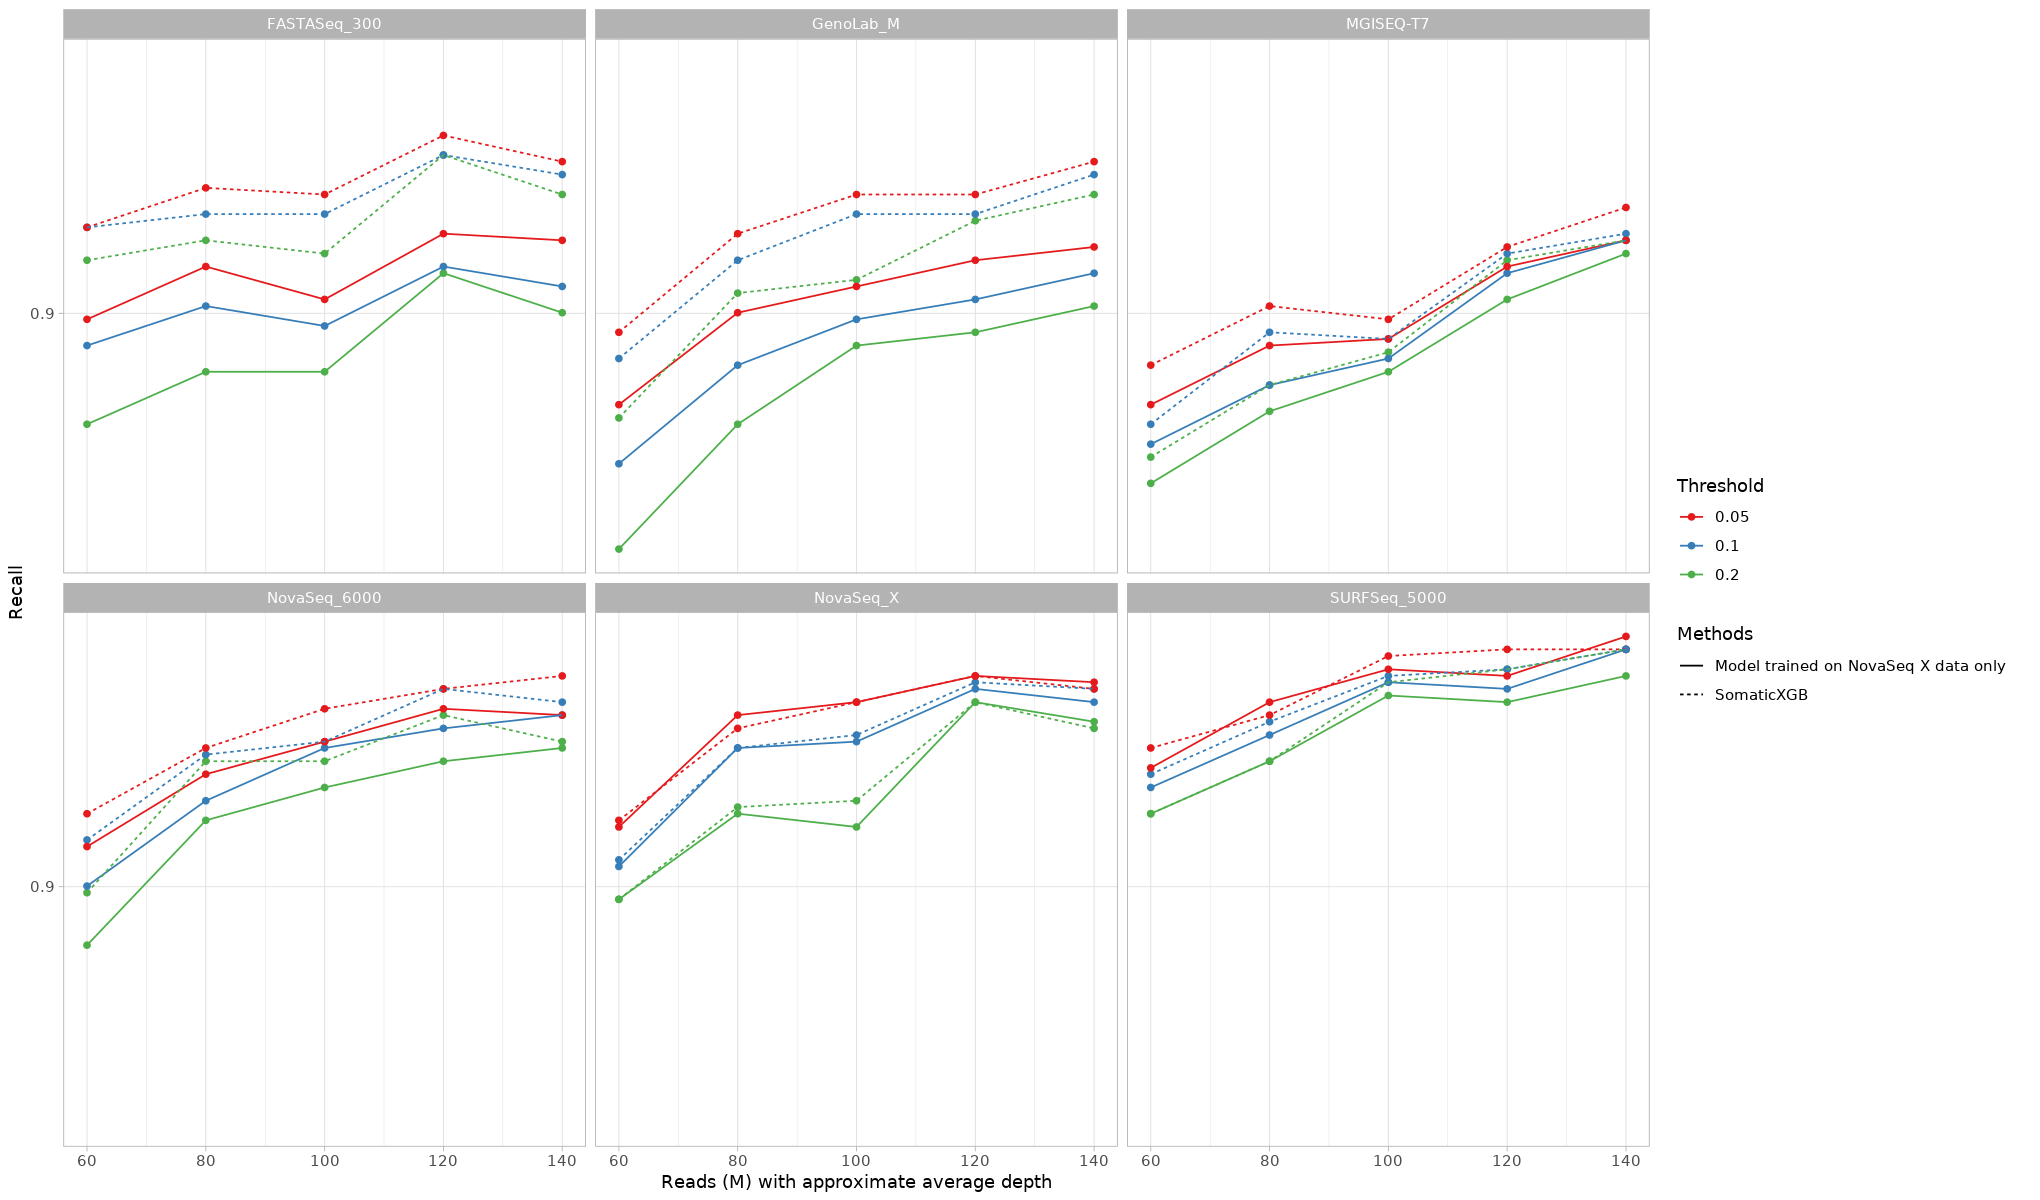

In [58]:
set_fig_size(17,10)
ggplot(modelstat45, aes(x = reads, y = Recall, color=Threshold, linetype = Methods)) +
  geom_point()+
  theme_light() +
  geom_line() +
  facet_wrap(~ plat) +
  scale_color_brewer(palette = "Set1") +
  scale_y_continuous(breaks = seq(0, 1, by = 0.1)) +
labs(x="Reads (M) with approximate average depth")

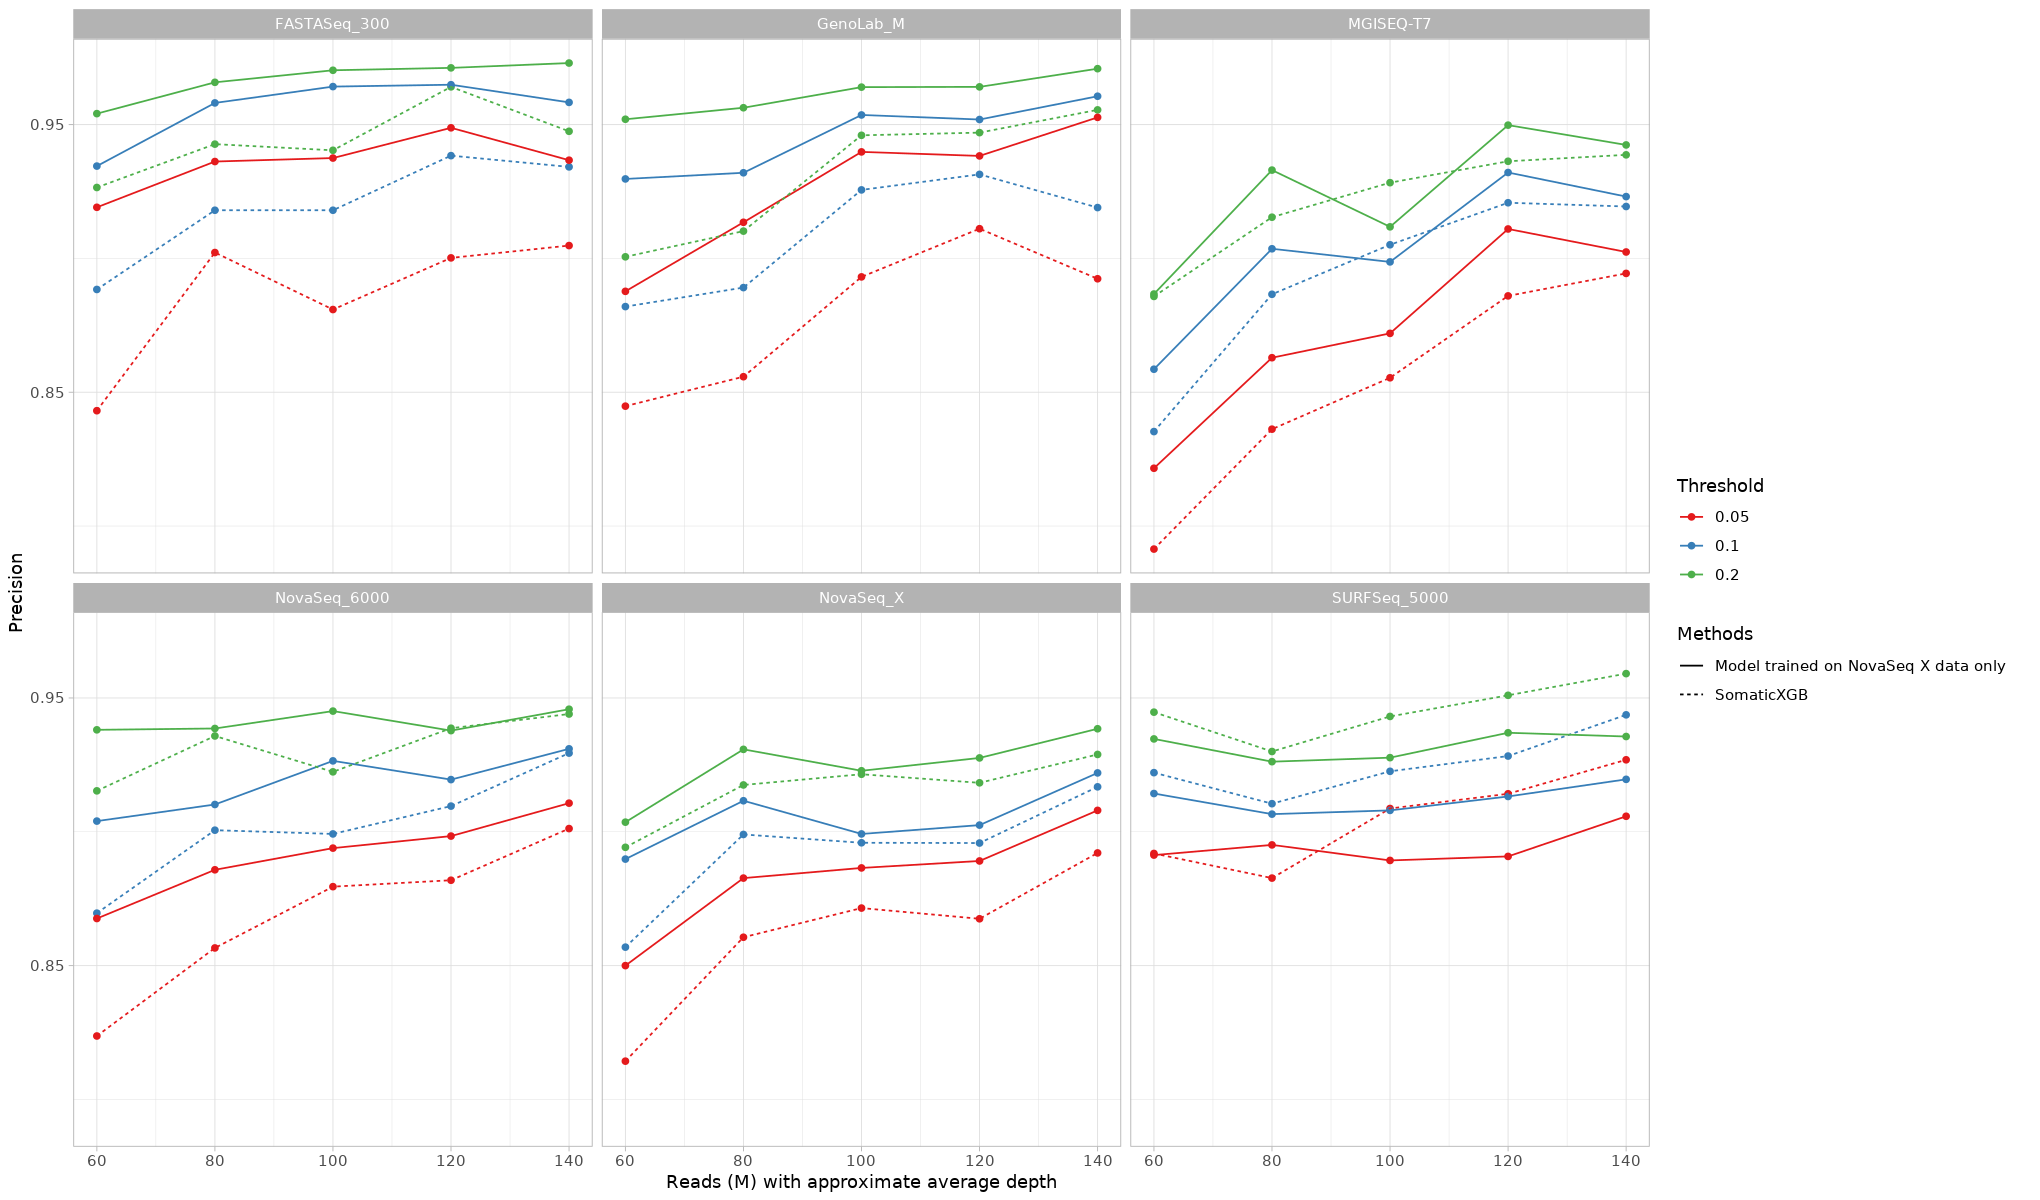

In [60]:
set_fig_size(17,10)
ggplot(modelstat45, aes(x = reads, y = Precision, color=Threshold, linetype = Methods)) +
  geom_point()+
  theme_light() +
  geom_line() +
  facet_wrap(~ plat) +
  scale_color_brewer(palette = "Set1") +
  scale_y_continuous(breaks = seq(0.75, 1, by = 0.1)) +
labs(x="Reads (M) with approximate average depth")

In [190]:
# 'NovaSeq_X'
test <- dt4554[plat=="SURFSeq_5000"] 
predictions1 <- predict(xgb_model, newdata=data.matrix(test[, features, with=FALSE]), type = "prob")
pr_curve1 <- pr.curve(scores.class0 = predictions1, weights.class0 = test$label, curve=T)
print(pr_curve1)

predictions2 <- predict(model_nx, newdata=data.matrix(test[, features, with=FALSE]), type = "prob")
pr_curve2 <- pr.curve(scores.class0 = predictions2, weights.class0 = test$label, curve=T)
print(pr_curve2)


  Precision-recall curve

    Area under curve (Integral):
     0.9944483 

    Area under curve (Davis & Goadrich):
     0.9944483 

    Curve for scores from  9.673197e-07  to  0.9999766 
    ( can be plotted with plot(x) )


  Precision-recall curve

    Area under curve (Integral):
     0.9924979 

    Area under curve (Davis & Goadrich):
     0.9924979 

    Curve for scores from  3.356879e-07  to  0.9999975 
    ( can be plotted with plot(x) )



In [186]:
pr_curve1.auc()

ERROR: Error in pr_curve1.auc(): could not find function "pr_curve1.auc"


In [1]:
set_fig_size(6.5,7)
plot(pr_curve1, main = "Precision-Recall Curves On MGISEQ-T7", xlab = "Recall", ylab = "Precision",col="blue", auc.main = FALSE)

# 然后，使用lines函数添加第二个PR曲线，并指定不同的颜色
plot(pr_curve2, col="red", add=TRUE, sub = "")

ERROR: Error in set_fig_size(6.5, 7): could not find function "set_fig_size"


In [113]:
ggplot(pr_curve1)

ERROR: [1m[33mError[39m in `fortify()`:[22m
[1m[22m[33m![39m `data` must be a [34m<data.frame>[39m, or an object coercible by `fortify()`,
  not a <PRROC> object.


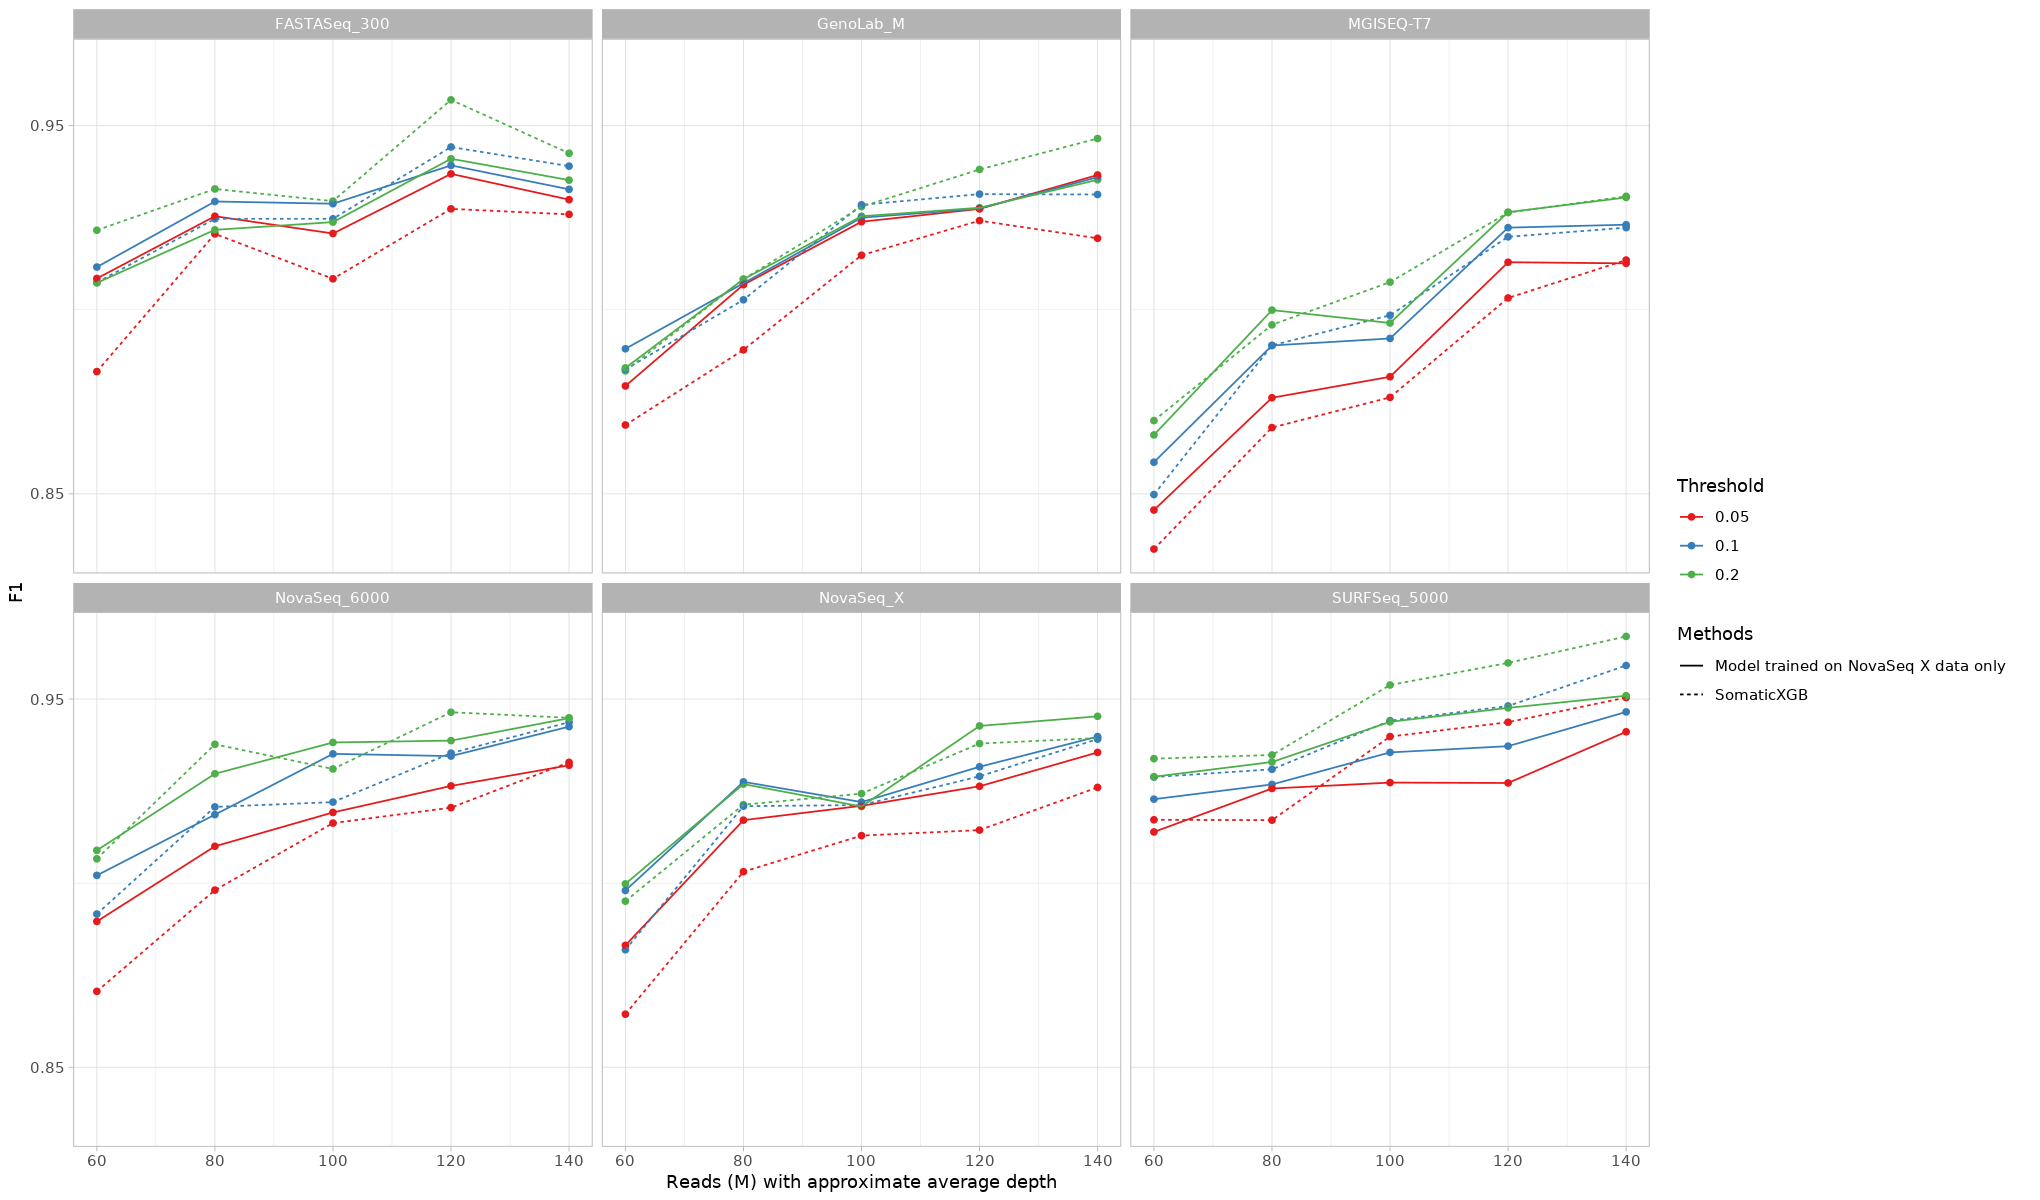

In [61]:
set_fig_size(17,10)
ggplot(modelstat45, aes(x = reads, y = F1, color=Threshold, linetype = Methods)) +
  geom_point()+
  theme_light() +
  geom_line() +
  facet_wrap(~ plat) +
  scale_color_brewer(palette = "Set1") +
  scale_y_continuous(breaks = seq(0.75, 1, by = 0.1)) +
labs(x="Reads (M) with approximate average depth")

In [200]:
twist <- fread("240801-twistpair/twist.txt",sep="\t")[, freq := tstrsplit(name,"_")[[2]]]

In [201]:
twist_1 <- twist[freq =='1']

In [202]:
twist_1[, k1 := paste0(tstrsplit(var,":")[[3]],tstrsplit(var,":")[[4]])]

In [203]:
head(twist_1)

var,DP,ECNT,MPOS,NALOD,NLOD,MBQ_REF,MBQ_ALT,MFRL_REF,MFRL_ALT,⋯,label,avg_mapping_quality,avg_basequality,avg_pos_as_fraction,avg_num_mismatches_as_fraction,avg_sum_mismatch_qualities,plat,name,freq,k1
<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,⋯,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
10:104263909:G:A,559,8,31,1.3400,6.01,20,28,163,154,⋯,0,60,34.33,0.44,0.02,45.33,GL,GL_1_GM23063001_GM23062701,1,GA
10:104263939:C:G,452,8,7,1.1600,3.91,36,20,170,160,⋯,0,60,36.00,0.19,0.01,37.67,GL,GL_1_GM23063001_GM23062701,1,CG
10:104263956:C:T,671,8,14,1.4000,6.92,36,20,173,141,⋯,0,60,36.00,0.21,0.03,53.60,GL,GL_1_GM23063001_GM23062701,1,CT
10:104264004:C:G,1148,8,51,1.6200,12.32,20,20,162,149,⋯,0,60,36.00,0.71,0.01,36.00,GL,GL_1_GM23063001_GM23062701,1,CG
10:104264031:G:A,1218,8,53,1.6600,13.23,20,20,162,154,⋯,0,60,36.00,0.72,0.01,36.00,GL,GL_1_GM23063001_GM23062701,1,GA
10:104264060:C:T,1231,8,50,-0.7657,9.37,20,20,162,189,⋯,0,60,36.00,0.78,0.01,68.33,GL,GL_1_GM23063001_GM23062701,1,CT


In [213]:
xgb_model <- xgb.load("model_0820")

In [435]:
predictions <- predict(xgb_model, newdata=data.matrix(twist_1[, features, with=FALSE]), type = "prob")
pr_curve <- pr.curve(scores.class0 = predictions, weights.class0 = twist_1$label,curve=T)
pr_auc <- pr_curve$auc.integral

In [436]:
pr_auc

[1] 0.933013

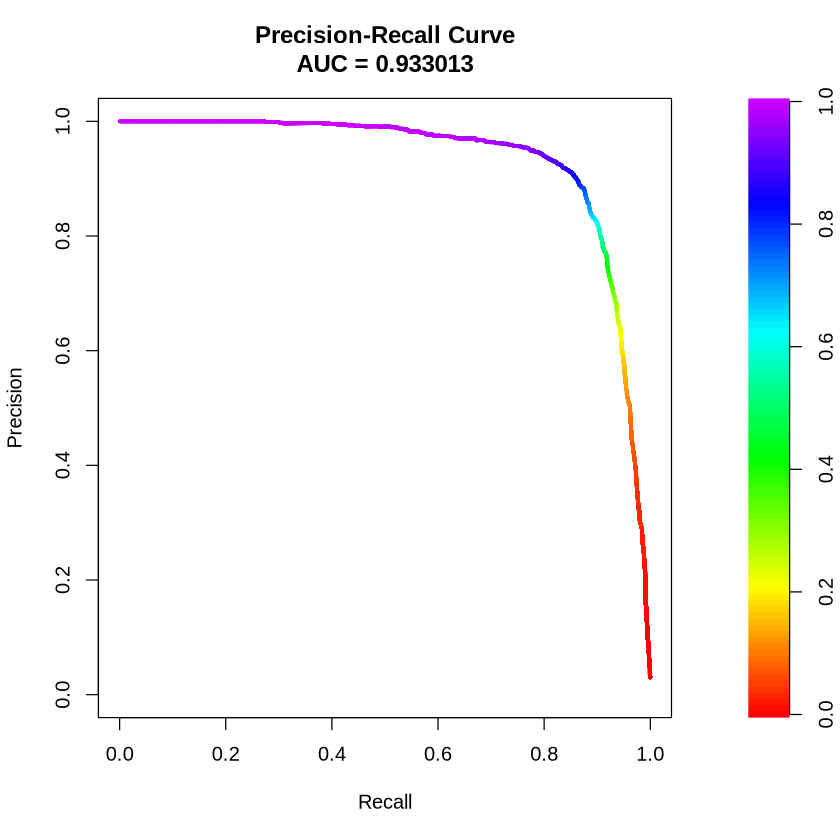

In [437]:
plot(pr_curve, main = "Precision-Recall Curve", xlab = "Recall", ylab = "Precision")

In [215]:
unique(twist_1[,plat])

[1] "GL" "SF" "NV" "NX"

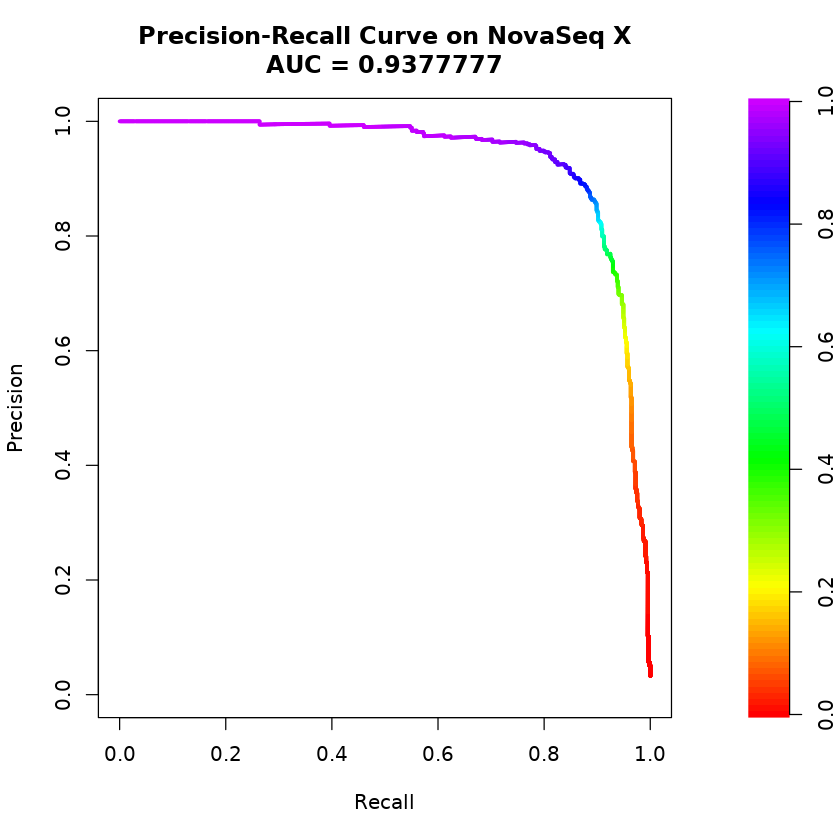

In [219]:
predictions <- predict(xgb_model, newdata=data.matrix(twist_1[plat=="NX"][, features, with=FALSE]), type = "prob")
pr_curve <- pr.curve(scores.class0 = predictions, weights.class0 = twist_1[plat=="NX"]$label,curve=T)
set_fig_size(7,7)
plot(pr_curve, main = "Precision-Recall Curve on NovaSeq X", xlab = "Recall", ylab = "Precision")

In [438]:
twist_v_fpf <- fread("240801-twistpair/twist_stat_v_fpf.txt", sep="\t")

In [439]:
twist_v_fpf[, freq := tstrsplit(name,"_")[[2]]]

In [440]:
head(twist_v_fpf)

caller,name,NPos,Nresults,truePos,falsePos,Recall,Precision,F1,freq
<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>
strelka2_mutect2,GL_05_GM23062704_GM23062701,227,71,16,55,0.0705,0.2254,0.1074,05
strelka2_mutect2,GL_05_GM24041605_GM24041603,227,106,18,88,0.0793,0.1698,0.1081,05
strelka2_mutect2,GL_05_GM24041606_GM24041604,227,85,17,68,0.0749,0.2000,0.1090,05
strelka2_mutect2,GL_1_GM23063001_GM23062701,227,223,146,77,0.6432,0.6547,0.6489,1
strelka2_mutect2,GL_1_GM24041607_GM24041603,227,235,157,78,0.6916,0.6681,0.6796,1
strelka2_mutect2,GL_1_GM24041608_GM24041604,227,220,153,67,0.6740,0.6955,0.6846,1


In [441]:
twist_v_fpf_1 <- twist_v_fpf[freq=='1']

In [442]:
twist_1$pred <- predict(xgb_model, data.matrix(twist_1[, features, with=FALSE]))

In [443]:
twist1_preds <- rbind(twist_1[pred>0.2][, Threshold:=0.2], twist_1[pred>0.1][, Threshold:=0.1], twist_1[pred>0.05][, Threshold:=0.05])

In [444]:
head(twist1_preds)

var,DP,ECNT,MPOS,NALOD,NLOD,MBQ_REF,MBQ_ALT,MFRL_REF,MFRL_ALT,⋯,avg_basequality,avg_pos_as_fraction,avg_num_mismatches_as_fraction,avg_sum_mismatch_qualities,plat,name,freq,k1,pred,Threshold
<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
10:104849438:C:T,3089,2,31,1.79,35.95,20,23,168,166,⋯,36.00,0.48,0.01,60.93,GL,GL_1_GM23063001_GM23062701,1,CT,0.2572310,0.2
10:112771362:A:T,1336,1,41,1.53,9.93,20,20,173,186,⋯,35.38,0.58,0.01,44.38,GL,GL_1_GM23063001_GM23062701,1,AT,0.2482777,0.2
10:123247516:T:C,3045,1,27,2.04,32.47,20,20,171,167,⋯,36.00,0.45,0.01,40.36,GL,GL_1_GM23063001_GM23062701,1,TC,0.9936721,0.2
10:123258034:A:T,2328,1,31,1.86,21.37,20,20,172,166,⋯,35.82,0.44,0.01,38.57,GL,GL_1_GM23063001_GM23062701,1,AT,0.9979709,0.2
10:123274774:A:G,3283,1,45,2.09,35.82,20,20,167,167,⋯,35.55,0.54,0.01,40.45,GL,GL_1_GM23063001_GM23062701,1,AG,0.9884455,0.2
10:123279677:G:C,2926,1,41,1.94,24.98,20,20,171,167,⋯,35.78,0.51,0.01,40.48,GL,GL_1_GM23063001_GM23062701,1,GC,0.9943051,0.2


In [461]:
twist1_preds_fp <- twist1_preds[label == 0]

In [462]:
nrow(twist1_preds_fp[Threshold==0.2][k1=='AC'])
nrow(twist1_preds_fp[Threshold==0.05][k1=='AC'])

[1] 3

[1] 7

In [463]:
dim(twist1_preds)
dim(twist1_preds_fp)

[1] 15540    30

[1] 8047   30

In [464]:
twist1_preds_fp[, Threshold := factor(Threshold)]

In [465]:
twist1_counts <- twist1_preds_fp %>%
  count(plat, Threshold, k1)

fwrite(twist1_counts, "twist1_counts.txt", sep="\t")

In [445]:
true <- fread("/mnt/nfsp2/projects/linyixin/240123-sfnv-twistpair-grch38/240221_grch37_all/twist_cfdna_pancancer_version1_hg19.vcf")

In [446]:
setnames(true, old="#CHROM", new="CHROM")

In [447]:
true[, CHROM := gsub("chr","",CHROM)]

In [448]:
true[, var := paste(CHROM,POS,REF,ALT,sep=":")]

In [449]:
true <- true[nchar(REF) == 1 & nchar(ALT) == 1]

In [450]:
model_stat <- twist1_preds[, .(NPos = nrow(true), Nresults = .N, truePos = sum(var %in% true$var), falsePos = sum(!var %in% true$var)), by = c("name","Threshold")] %>% 
.[, Recall := round(truePos/NPos,4)] %>%
.[, Precision := round(truePos/Nresults,4)] %>%
.[, F1 := round(2*Recall*Precision/(Recall+Precision),4)] %>%
.[, Platforms := tstrsplit(name,"_")[[1]]]

In [451]:
model_stat[, Method := paste0("SomaticXGB (threshold: ",Threshold,")")]

In [452]:
model_stat <- model_stat[,name:=NULL]
model_stat <- model_stat[,Threshold:=NULL]

In [453]:
head(model_stat)

NPos,Nresults,truePos,falsePos,Recall,Precision,F1,Platforms,Method
<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
227,365,211,154,0.9295,0.5781,0.7128,GL,SomaticXGB (threshold: 0.2)
227,341,210,131,0.9251,0.6158,0.7394,GL,SomaticXGB (threshold: 0.2)
227,347,209,138,0.9207,0.6023,0.7282,GL,SomaticXGB (threshold: 0.2)
227,330,200,130,0.8811,0.6061,0.7182,SF,SomaticXGB (threshold: 0.2)
227,315,210,105,0.9251,0.6667,0.7749,SF,SomaticXGB (threshold: 0.2)
227,293,206,87,0.9075,0.7031,0.7923,SF,SomaticXGB (threshold: 0.2)


In [454]:
twist_v_fpf_1[, Platforms := tstrsplit(name,"_")[[1]]]

In [455]:
twist_v_fpf_1[, name:=NULL]
twist_v_fpf_1[, freq:=NULL]

In [456]:
setnames(twist_v_fpf_1, old="caller", new="Method")

In [457]:
head(twist_v_fpf_1)

Method,NPos,Nresults,truePos,falsePos,Recall,Precision,F1,Platforms
<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>
strelka2_mutect2,227,223,146,77,0.6432,0.6547,0.6489,GL
strelka2_mutect2,227,235,157,78,0.6916,0.6681,0.6796,GL
strelka2_mutect2,227,220,153,67,0.6740,0.6955,0.6846,GL
strelka2_mutect2,227,250,158,92,0.6960,0.6320,0.6625,SF
strelka2_mutect2,227,253,167,86,0.7357,0.6601,0.6959,SF
strelka2_mutect2,227,258,167,91,0.7357,0.6473,0.6887,SF


In [458]:
stat <- rbind(twist_v_fpf_1, model_stat)

In [459]:
stat

Method,NPos,Nresults,truePos,falsePos,Recall,Precision,F1,Platforms
<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>
strelka2_mutect2,227,223,146,77,0.6432,0.6547,0.6489,GL
strelka2_mutect2,227,235,157,78,0.6916,0.6681,0.6796,GL
strelka2_mutect2,227,220,153,67,0.6740,0.6955,0.6846,GL
strelka2_mutect2,227,250,158,92,0.6960,0.6320,0.6625,SF
strelka2_mutect2,227,253,167,86,0.7357,0.6601,0.6959,SF
strelka2_mutect2,227,258,167,91,0.7357,0.6473,0.6887,SF
strelka2_mutect2,227,142,103,39,0.4537,0.7254,0.5582,NV
strelka2_mutect2,227,170,124,46,0.5463,0.7294,0.6247,NV
strelka2_mutect2,227,152,106,46,0.4670,0.6974,0.5594,NV


In [460]:
fwrite(stat,"stat_twist.txt",sep="\t")

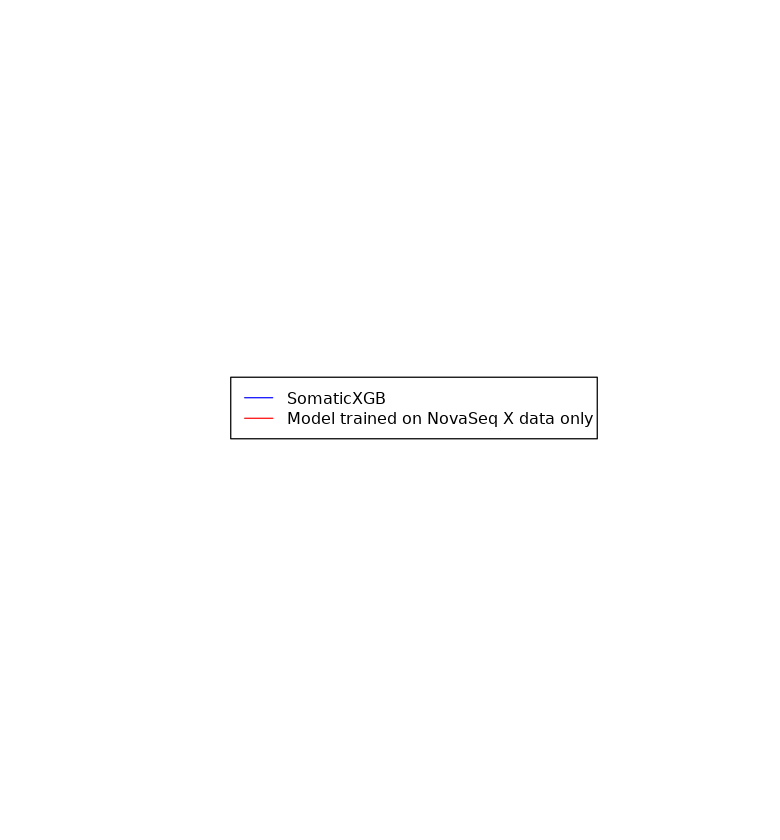

In [148]:
# 创建一个空白的绘图区域
plot.new()

# 设置坐标轴范围
plot.window(xlim = c(0, 1), ylim = c(0, 1))

# 绘制图例
legend("center", legend = c("SomaticXGB", "Model trained on NovaSeq X data only"), col = c("blue", "red"), lty = 1, cex = 0.8)